In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42


In [2]:
X, y = make_moons(
    n_samples=700,
    noise=0.28,
    random_state=RANDOM_STATE
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=200,
    test_size=500,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)


Training features: (200, 2)
Training labels: (200,)
Test features: (500, 2)
Test labels: (500,)


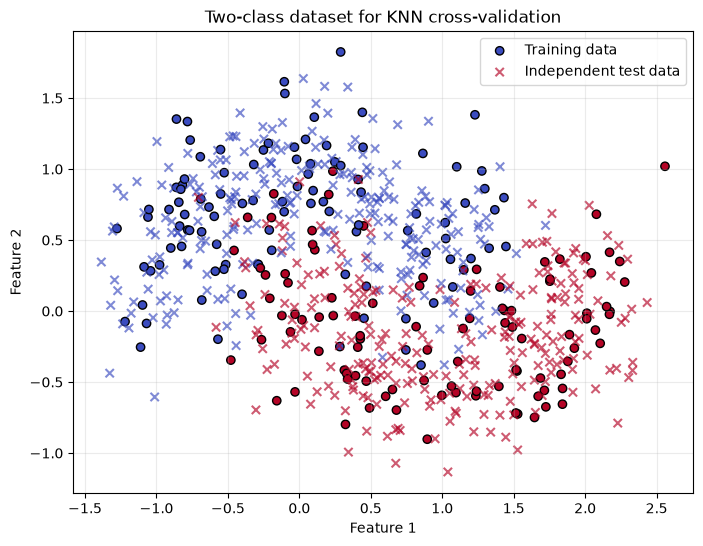

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train, cmap="coolwarm",
    marker="o", edgecolors="black",
    label="Training data"
)

plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=y_test, cmap="coolwarm",
    marker="x", alpha=0.65,
    label="Independent test data"
)

plt.title("Two-class dataset for KNN cross-validation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [4]:
k_values = range(1, 121)

training_errors = []
test_errors = []
cv_errors = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for k in k_values:
    # Training and independent test errors
    model = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    training_errors.append(np.mean(train_pred != y_train))
    test_errors.append(np.mean(test_pred != y_test))

    # Five-fold cross-validation error on the training set
    fold_errors = []

    for train_idx, validation_idx in cv.split(X_train, y_train):
        X_fold_train = X_train[train_idx]
        y_fold_train = y_train[train_idx]
        X_fold_validation = X_train[validation_idx]
        y_fold_validation = y_train[validation_idx]

        fold_model = KNeighborsClassifier(
            n_neighbors=k,
            metric="euclidean"
        )
        fold_model.fit(X_fold_train, y_fold_train)

        validation_pred = fold_model.predict(X_fold_validation)
        fold_errors.append(
            np.mean(validation_pred != y_fold_validation)
        )

    cv_errors.append(np.mean(fold_errors))

print("Completed evaluation for", len(list(k_values)), "K values.")


Completed evaluation for 120 K values.


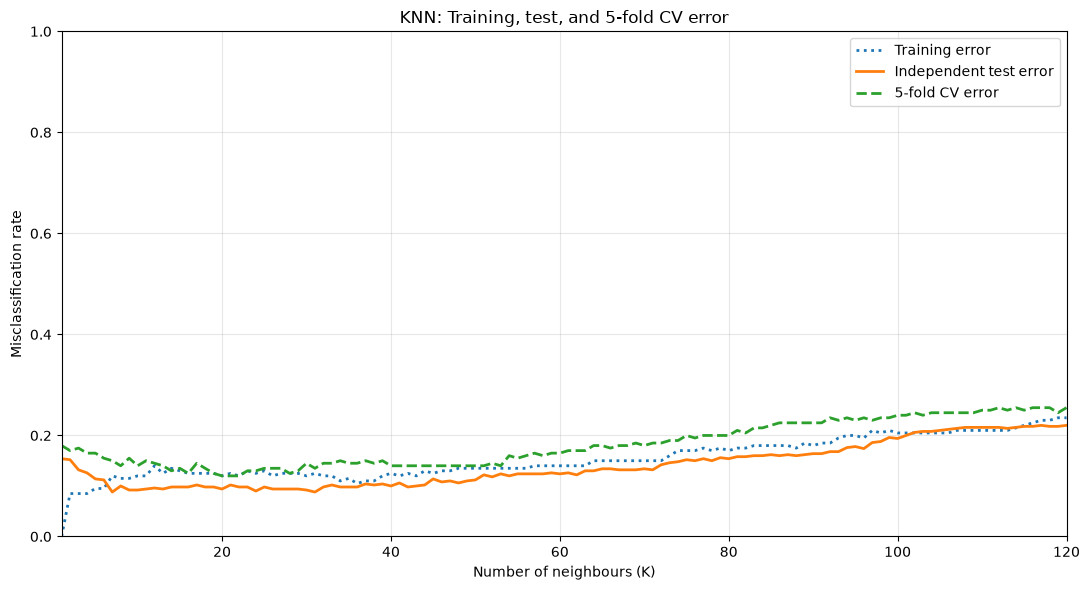

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    list(k_values), training_errors,
    linestyle=":", linewidth=2,
    label="Training error"
)
plt.plot(
    list(k_values), test_errors, 
    linewidth=2,
    label="Independent test error"
)
plt.plot(
    list(k_values), cv_errors,
    linestyle="--", linewidth=2,
    label="5-fold CV error"
)

plt.xlabel("Number of neighbours (K)")
plt.ylabel("Misclassification rate")
plt.title("KNN: Training, test, and 5-fold CV error")
plt.xlim(1, 120)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
k_list = list(k_values)

best_test_k = k_list[int(np.argmin(test_errors))]
best_cv_k = k_list[int(np.argmin(cv_errors))]

summary = pd.DataFrame({
    "Measure": [
        "K with minimum error",
        "Minimum misclassification rate (%)"
    ],
    "Independent test": [
        best_test_k,
        100 * min(test_errors)
    ],
    "5-fold CV": [
        best_cv_k,
        100 * min(cv_errors)
    ]
})

display(summary.round(2))


,Measure,Independent test,5-fold CV
0,K with minimum error,7.0,20.0
1,Minimum misclassification rate (%),8.8,12.0


In [7]:
selected_k = [1, 3, 5, 10, 20, 40, 60, 80, 100, 120]

selected_results = pd.DataFrame({
    "K": selected_k,
    "Training error (%)": [100 * training_errors[k - 1] for k in selected_k],
    "Test error (%)": [100 * test_errors[k - 1] for k in selected_k],
    "5-fold CV error (%)": [100 * cv_errors[k - 1] for k in selected_k]
})

display(selected_results.round(2))


,K,Training error (%),Test error (%),5-fold CV error (%)
0,1,0.0,15.4,18.0
1,3,8.5,13.2,17.5
2,5,9.5,11.4,16.5
3,10,12.0,9.2,14.0
4,20,12.0,9.4,12.0
5,40,12.5,10.0,14.0
6,60,14.0,12.4,16.5
7,80,17.0,15.4,20.0
8,100,20.5,19.4,24.0
9,120,23.5,22.0,25.5
